# Семинар 8. Классификация изображений классическими методами (HOG)

**Объект:** кошка. **Положительный класс (1)** — изображения с кошкой, **отрицательный класс (0)** — изображения без кошки. В качестве отрицательного класса взяты **собаки**: это тематически близкие объекты (домашние животные со схожей формой тела, шерстью, сходным фоном — дом, диван, трава), поэтому задача нетривиальна.

**Источник данных:** Oxford-IIIT Pet Dataset (Parkhi et al., *Cats and Dogs*, CVPR 2012; лицензия CC BY-SA 4.0). Из него скриптом `prepare_data.py` отобраны изображения равномерно по породам (12 пород кошек, 25 пород собак), уменьшены до размера не более 400 пикселей по большей стороне и сохранены в папку `data/`:

| Папка | Содержимое | Назначение |
|---|---|---|
| `data/main/cat` | 100 изображений кошек | основной набор, шаг 1 |
| `data/main/dog` | 100 изображений собак | основной набор, шаг 1 |
| `data/extra/cat`, `data/extra/dog` | по 60 изображений | дополнительные данные, шаг 2 |
| `data/bboxes.csv` | рамки головы животного | детектор, шаг 3 |

Для всех изображений в датасете имеется ручная разметка ограничивающей рамки **головы** животного; она используется в шаге 3 для обучения и проверки детектора (объект детекции — голова кошки).

**Структура работы:** шаг 1 — HOG-признаки, таблица признаков, сравнение пяти классификаторов, визуальный анализ ошибок; шаг 2 — аугментация и дополнительные данные; шаг 3 — детектор HOG + линейный SVM (Dalal & Triggs, 2005) и оценка по IoU.

In [1]:
import os
for _v in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"]:
    os.environ.setdefault(_v, "1")          # однопоточные вычисления: воспроизводимость и стабильность в Jupyter
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from IPython.display import display, Markdown

from skimage.feature import hog
from skimage import exposure
from skimage.transform import resize, rescale, AffineTransform, warp
from skimage.color import rgb2gray

from sklearn.model_selection import (train_test_split, GridSearchCV, StratifiedKFold,
                                     RepeatedStratifiedKFold, cross_val_score)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC, LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.base import clone
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, roc_curve)

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 200)
SEED = 42
DATA = Path("data")
BLUE, ORANGE, GREEN, RED = "#2a78d6", "#eb6834", "#1baf7a", "#d63a2a"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})

---
## Шаг 1. Базовая часть

### 1.1. Набор изображений

Основной набор: {'cat': 100, 'dog': 100}
Дополнительный набор: {'cat': 60, 'dog': 60}
Пород кошек: 12, пород собак: 25
Размеры изображений (ширина×высота): от [144, 108] до [400, 400]


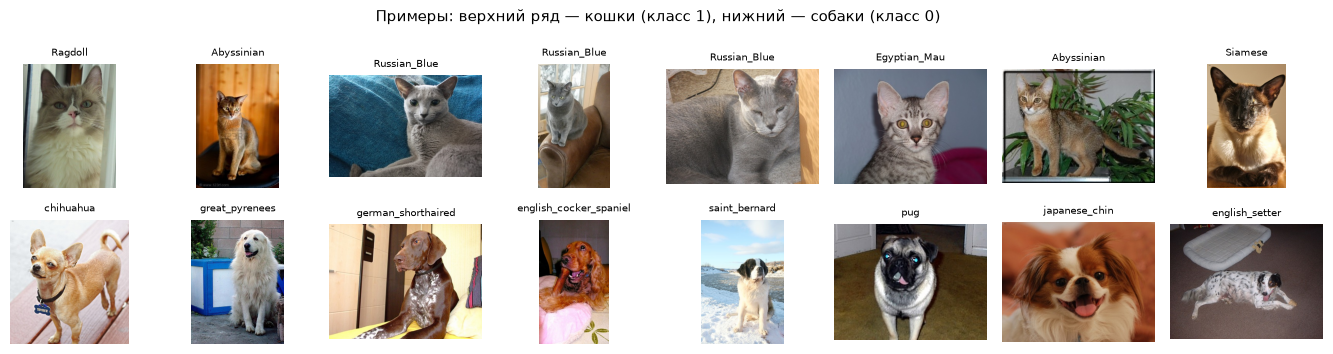

In [2]:
meta = pd.read_csv(DATA / "bboxes.csv")
meta["label"] = (meta["class"] == "cat").astype(int)
main = meta[meta["part"] == "main"].reset_index(drop=True)
extra = meta[meta["part"] == "extra"].reset_index(drop=True)

print("Основной набор:", main["class"].value_counts().to_dict())
print("Дополнительный набор:", extra["class"].value_counts().to_dict())
print(f"Пород кошек: {main.loc[main.label == 1, 'breed'].nunique()}, пород собак: {main.loc[main.label == 0, 'breed'].nunique()}")
print("Размеры изображений (ширина×высота): от", main[["width", "height"]].min().tolist(), "до", main[["width", "height"]].max().tolist())

def load_rgb(rel_path):
    return np.asarray(Image.open(DATA / rel_path).convert("RGB"))

def show_grid(rows, ncols=8, title=None, size=1.7, caption=None, frame=None):
    n = len(rows)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, size * nrows * 1.05))
    for ax in np.ravel(axes):
        ax.axis("off")
    for ax, (_, r) in zip(np.ravel(axes), rows.iterrows()):
        ax.imshow(load_rgb(r["file"]))
        if caption:
            ax.set_title(caption(r), fontsize=7)
        if frame:
            color = frame(r)
            for s in ax.spines.values():
                s.set_visible(True); s.set_edgecolor(color); s.set_linewidth(3)
            ax.axis("on"); ax.set_xticks([]); ax.set_yticks([])
    if title:
        fig.suptitle(title, fontsize=11)
    fig.tight_layout()
    plt.show()

sample = pd.concat([main[main.label == 1].sample(8, random_state=1), main[main.label == 0].sample(8, random_state=1)])
show_grid(sample, ncols=8, title="Примеры: верхний ряд — кошки (класс 1), нижний — собаки (класс 0)",
          caption=lambda r: r["breed"])

### 1.2. Признаки HOG и таблица признаков

Метод **гистограмм ориентированных градиентов** (HOG, Dalal & Triggs, 2005) описывает форму объекта распределением направлений краёв:

1. **Подсчёт градиентов.** Для каждого пикселя вычисляются производные $G_x$, $G_y$ (свёртка с $[-1, 0, 1]$), модуль $|G| = \sqrt{G_x^2 + G_y^2}$ и направление $\theta = \operatorname{arctg}(G_y / G_x)$ (беззнаковое, $0°$–$180°$). Градиент указывает направление наибольшего роста яркости, поэтому на границах объекта он перпендикулярен контуру.
2. **Гистограммы по ячейкам.** Изображение делится на ячейки (здесь 16×16 пикселей); в каждой ячейке строится гистограмма из 9 корзин по направлению, вклад пикселя равен модулю градиента.
3. **Нормализация по блокам.** Соседние ячейки объединяются в перекрывающиеся блоки 2×2, вектор блока нормируется (схема L2-Hys). Это даёт устойчивость к изменениям освещённости и контраста.
4. **Стыковка** векторов всех блоков в один дескриптор.

Перед вычислением HOG изображения переводятся в оттенки серого и приводятся к единому размеру 128×128 (пропорции при этом искажаются, но длина вектора признаков становится одинаковой). Размер дескриптора: $7 \times 7$ блоков $\times\, 2 \times 2$ ячейки $\times\, 9$ направлений $= 1764$ признака.

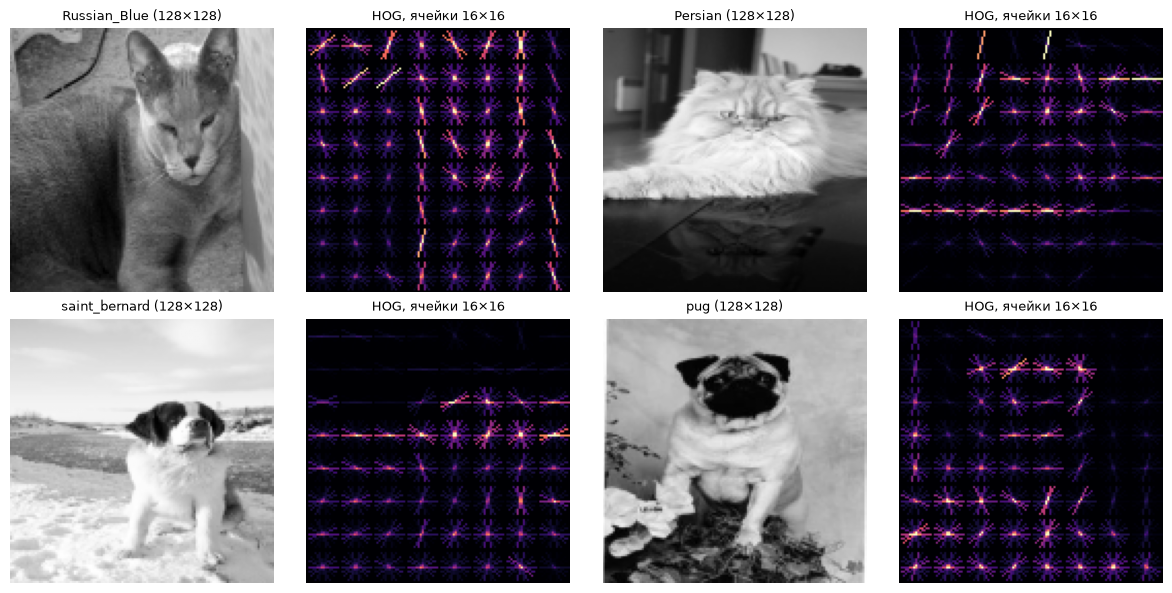

In [3]:
IMG_SIZE = (128, 128)
HOG_PARAMS = dict(orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2), block_norm="L2-Hys")

def to_gray(rgb, size=IMG_SIZE):
    return resize(rgb2gray(rgb), size, anti_aliasing=True)

def hog_features(gray):
    return hog(gray, **HOG_PARAMS, feature_vector=True)

# Визуализация HOG для кошки и собаки
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for row, cls in enumerate([1, 0]):
    for k, (_, r) in enumerate(main[main.label == cls].sample(2, random_state=3).iterrows()):
        g = to_gray(load_rgb(r["file"]))
        _, vis = hog(g, **HOG_PARAMS, visualize=True)
        axes[row, 2 * k].imshow(g, cmap="gray"); axes[row, 2 * k].set_title(f"{r['breed']} (128×128)", fontsize=9)
        axes[row, 2 * k + 1].imshow(exposure.rescale_intensity(vis, in_range=(0, vis.max() / 2)), cmap="magma")
        axes[row, 2 * k + 1].set_title("HOG, ячейки 16×16", fontsize=9)
for ax in axes.ravel():
    ax.axis("off")
fig.tight_layout(); plt.show()

In [4]:
t0 = time.time()
X_all = np.array([hog_features(to_gray(load_rgb(f))) for f in main["file"]])
print(f"HOG вычислен для {len(X_all)} изображений за {time.time() - t0:.1f} с; длина вектора: {X_all.shape[1]}")

hog_table = pd.concat([main[["file", "label"]],
                       pd.DataFrame(X_all, columns=[f"hog_{i}" for i in range(X_all.shape[1])])], axis=1)
hog_table.to_csv(DATA / "hog_features.csv", index=False)
print("Таблица сохранена в data/hog_features.csv:", hog_table.shape)
display(hog_table.iloc[[0, 1, 2, -3, -2, -1], :8].round(4))

HOG вычислен для 200 изображений за 3.4 с; длина вектора: 1764


Таблица сохранена в data/hog_features.csv: (200, 1766)


,file,label,hog_0,hog_1,hog_2,hog_3,hog_4,hog_5
0,main/cat/Abyssinian_136.jpg,1,0.1722,0.0986,0.0746,0.0437,0.1478,0.0490
1,main/cat/Bengal_173.jpg,1,0.2707,0.0136,0.0078,0.0015,0.0137,0.0009
2,main/cat/Birman_134.jpg,1,0.1344,0.1471,0.2673,0.3014,0.1862,0.1025
197,main/dog/staffordshire_bull_terrier_17.jpg,0,0.3089,0.0615,0.0275,0.1940,0.3089,0.0658
198,main/dog/wheaten_terrier_181.jpg,0,0.1947,0.0780,0.1533,0.1659,0.1939,0.2068
199,main/dog/yorkshire_terrier_16.jpg,0,0.2524,0.1490,0.1592,0.1473,0.2524,0.2524


In [5]:
idx_train, idx_test = train_test_split(np.arange(len(main)), test_size=0.2, stratify=main["label"], random_state=SEED)
X_train, X_test = X_all[idx_train], X_all[idx_test]
y_train, y_test = main["label"].values[idx_train], main["label"].values[idx_test]
main["split"] = "train"
main.loc[idx_test, "split"] = "test"
print(f"Обучающая выборка: {len(idx_train)} (кошек {y_train.sum()}), тестовая: {len(idx_test)} (кошек {y_test.sum()})")

Обучающая выборка: 160 (кошек 80), тестовая: 40 (кошек 20)


### 1.3. Обучение и сравнение моделей

Сравниваются пять методов классификации различной природы:

| Модель | Идея |
|---|---|
| Логистическая регрессия | линейная модель, вероятность класса через сигмоиду; параметры находятся градиентным спуском по функции потерь (log-loss) с L2-регуляризацией |
| Линейный SVM | линейная разделяющая гиперплоскость с максимальным зазором (классическая пара для HOG у Dalal & Triggs) |
| SVM с RBF-ядром | нелинейная граница за счёт гауссова ядра |
| Случайный лес | ансамбль решающих деревьев на случайных подвыборках признаков |
| k ближайших соседей | класс по большинству среди ближайших объектов (после PCA до 50 компонент, т. к. в пространстве 1764 признаков расстояния малоинформативны) |

Гиперпараметры подбираются **перекрёстной проверкой (5 фолдов) только на обучающей выборке**, затем модель оценивается на отложенной тестовой выборке (40 изображений). Поскольку тестовая выборка мала (одна ошибка = 2.5 п.п. точности), дополнительно для каждой модели с найденными гиперпараметрами выполняется **повторная перекрёстная проверка 5×5 на всех 200 изображениях** — она даёт более устойчивую оценку.

In [6]:
MODELS = {
    "Логистическая регрессия": (make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
                                {"logisticregression__C": [1e-4, 1e-3, 1e-2, 1e-1]}),
    "Линейный SVM": (make_pipeline(StandardScaler(), LinearSVC(max_iter=20000)),
                     {"linearsvc__C": [1e-5, 1e-4, 1e-3, 1e-2]}),
    "SVM (RBF)": (make_pipeline(StandardScaler(), SVC(kernel="rbf")),
                  {"svc__C": [1, 10, 100], "svc__gamma": ["scale", 1e-4, 3e-4]}),
    "Случайный лес": (RandomForestClassifier(n_estimators=500, random_state=SEED, n_jobs=1),
                      {"max_features": ["sqrt", 0.05], "min_samples_leaf": [1, 3]}),
    "kNN (PCA-50)": (make_pipeline(StandardScaler(), PCA(50, random_state=SEED), KNeighborsClassifier()),
                     {"kneighborsclassifier__n_neighbors": [3, 7, 15], "kneighborsclassifier__weights": ["uniform", "distance"]}),
}

def scores_of(model, X):
    return model.decision_function(X) if hasattr(model, "decision_function") else model.predict_proba(X)[:, 1]

cv5 = StratifiedKFold(5, shuffle=True, random_state=SEED)
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)
fitted, rows, test_scores = {}, [], {}
for name, (pipe, grid) in MODELS.items():
    gs = GridSearchCV(pipe, grid, cv=cv5, scoring="accuracy", n_jobs=1).fit(X_train, y_train)
    model = gs.best_estimator_
    fitted[name] = model
    pred = model.predict(X_test)
    test_scores[name] = scores_of(model, X_test)
    rep = cross_val_score(clone(model), X_all, main["label"].values, cv=rcv, scoring="accuracy", n_jobs=1)
    rows.append({"Модель": name,
                 "Параметры": ", ".join(f"{k.split('__')[-1]}={v}" for k, v in gs.best_params_.items()),
                 "CV на train": gs.best_score_, "Accuracy (test)": accuracy_score(y_test, pred),
                 "Precision": precision_score(y_test, pred), "Recall": recall_score(y_test, pred),
                 "F1": f1_score(y_test, pred), "ROC-AUC": roc_auc_score(y_test, test_scores[name]),
                 "CV 5×5 (все 200)": f"{rep.mean():.3f} ± {rep.std():.3f}", "_rep": rep.mean()})

results1 = pd.DataFrame(rows).set_index("Модель")
display(results1.drop(columns="_rep").round(3))
BEST = results1["_rep"].idxmax()
print("Лучшая модель по повторной перекрёстной проверке:", BEST)

,Параметры,CV на train,Accuracy (test),Precision,Recall,F1,ROC-AUC,CV 5×5 (все 200)
Модель,,,,,,,,
Логистическая регрессия,C=0.0001,0.675,0.700,0.682,0.75,0.714,0.745,0.683 ± 0.042
Линейный SVM,C=1e-05,0.675,0.700,0.682,0.75,0.714,0.735,0.680 ± 0.041
SVM (RBF),"C=1, gamma=scale",0.712,0.650,0.625,0.75,0.682,0.718,0.692 ± 0.042
Случайный лес,"max_features=sqrt, min_samples_leaf=3",0.712,0.625,0.600,0.75,0.667,0.690,0.680 ± 0.045
kNN (PCA-50),"n_neighbors=3, weights=uniform",0.600,0.475,0.429,0.15,0.222,0.490,0.555 ± 0.052


Лучшая модель по повторной перекрёстной проверке: SVM (RBF)


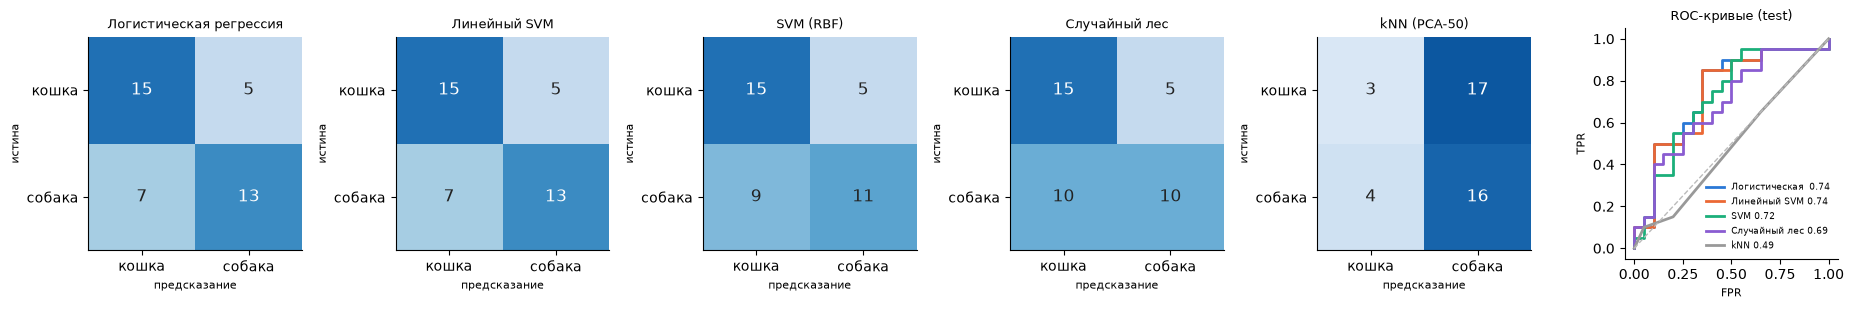

In [7]:
fig, axes = plt.subplots(1, len(fitted) + 1, figsize=(3.1 * (len(fitted) + 1), 3.2))
for ax, (name, model) in zip(axes, fitted.items()):
    cm = confusion_matrix(y_test, model.predict(X_test), labels=[1, 0])
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=20)
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, v, ha="center", va="center", fontsize=12, color="white" if v > 12 else "#222")
    ax.set_xticks([0, 1], ["кошка", "собака"]); ax.set_yticks([0, 1], ["кошка", "собака"])
    ax.set_xlabel("предсказание", fontsize=8); ax.set_ylabel("истина", fontsize=8)
    ax.set_title(name, fontsize=9)
ax = axes[-1]
for (name, s), c in zip(test_scores.items(), [BLUE, ORANGE, GREEN, "#8a5cd1", "#999999"]):
    fpr, tpr, _ = roc_curve(y_test, s)
    ax.plot(fpr, tpr, color=c, lw=2, label=f"{name.split(' (')[0][:14]} {roc_auc_score(y_test, s):.2f}")
ax.plot([0, 1], [0, 1], ls="--", color="#bbb", lw=1)
ax.set_title("ROC-кривые (test)", fontsize=9); ax.set_xlabel("FPR", fontsize=8); ax.set_ylabel("TPR", fontsize=8)
ax.legend(fontsize=6.5, frameon=False, loc="lower right")
fig.tight_layout(); plt.show()

### 1.4. Визуальный анализ результатов

Ниже показаны все 40 тестовых изображений с предсказанием лучшей модели (зелёная рамка — верно, красная — ошибка), а также изображения, на которых ошибается большинство моделей. Для количественной проверки визуальных наблюдений для каждого тестового изображения рассчитываются простые характеристики: доля площади, занимаемая головой животного (по разметке), средняя яркость, контраст (стандартное отклонение яркости) и «загромождённость» фона — средний модуль градиента.

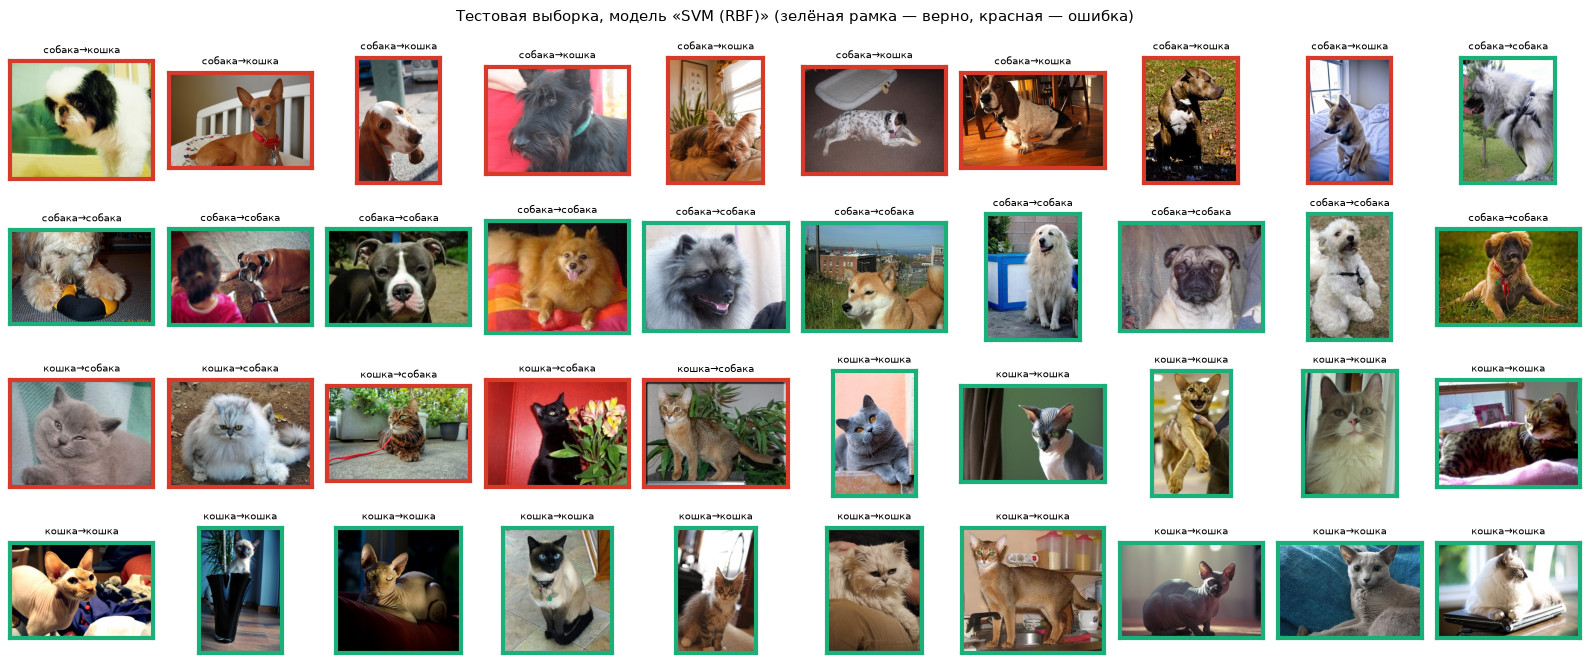

In [8]:
test_df = main.loc[idx_test].copy()
test_df["pred"] = fitted[BEST].predict(X_test)
test_df["score"] = scores_of(fitted[BEST], X_test)
test_df["n_wrong"] = sum((m.predict(X_test) != y_test).astype(int) for m in fitted.values())
test_df["ok"] = test_df["pred"] == test_df["label"]

name_ru = {1: "кошка", 0: "собака"}
show_grid(test_df.sort_values(["label", "ok"]), ncols=10, size=1.6,
          title=f"Тестовая выборка, модель «{BEST}» (зелёная рамка — верно, красная — ошибка)",
          caption=lambda r: f"{name_ru[r['label']]}→{name_ru[r['pred']]}",
          frame=lambda r: GREEN if r["ok"] else RED)

Изображений, на которых ошибаются ≥3 из 5 моделей: 13


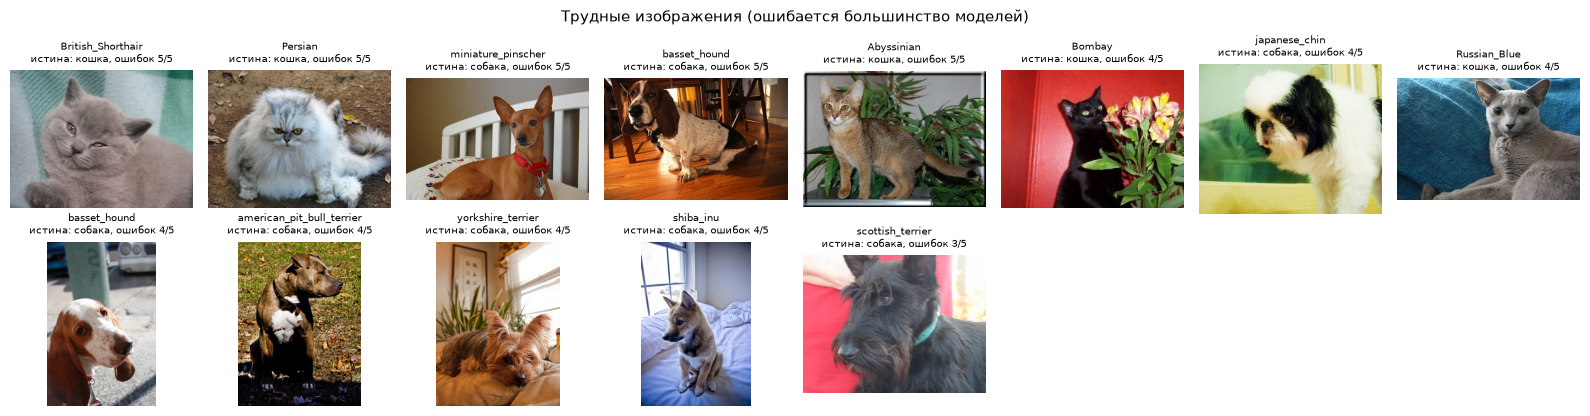

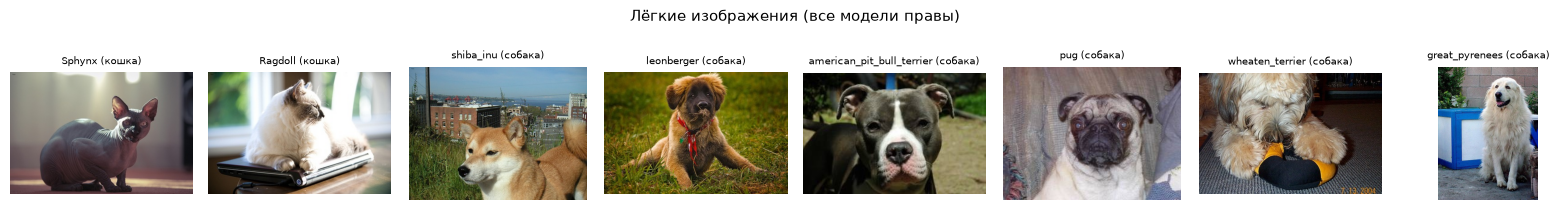

In [9]:
hard = test_df[test_df["n_wrong"] >= 3].sort_values("n_wrong", ascending=False)
print(f"Изображений, на которых ошибаются ≥3 из 5 моделей: {len(hard)}")
show_grid(hard, ncols=min(8, max(len(hard), 1)), size=2.0, title="Трудные изображения (ошибается большинство моделей)",
          caption=lambda r: f"{r['breed']}\nистина: {name_ru[r['label']]}, ошибок {r['n_wrong']}/5")
easy = test_df[test_df["n_wrong"] == 0]
show_grid(easy.sample(min(8, len(easy)), random_state=0), ncols=8, size=2.0,
          title="Лёгкие изображения (все модели правы)", caption=lambda r: f"{r['breed']} ({name_ru[r['label']]})")

In [10]:
def image_stats(r):
    g = rgb2gray(load_rgb(r["file"]))
    gy, gx = np.gradient(g)
    head_share = (r["xmax"] - r["xmin"]) * (r["ymax"] - r["ymin"]) / (r["width"] * r["height"])
    return pd.Series({"Доля головы в кадре": head_share, "Яркость": g.mean(),
                      "Контраст": g.std(), "Ср. модуль градиента": np.hypot(gx, gy).mean()})

stats = test_df.apply(image_stats, axis=1)
stats["Группа"] = np.where(test_df["n_wrong"] >= 3, "трудные (≥3 ошибок)",
                  np.where(test_df["n_wrong"] == 0, "лёгкие (0 ошибок)", "промежуточные"))
display(stats.groupby("Группа").agg(["mean"]).round(3).droplevel(1, axis=1)
        .join(stats["Группа"].value_counts().rename("N")))
print("Ошибки лучшей модели по классам:",
      {name_ru[c]: int(((test_df.label == c) & ~test_df.ok).sum()) for c in [1, 0]})

,Доля головы в кадре,Яркость,Контраст,Ср. модуль градиента,N
Группа,,,,,
лёгкие (0 ошибок),0.192,0.422,0.211,0.036,12
промежуточные,0.165,0.446,0.233,0.034,15
трудные (≥3 ошибок),0.219,0.450,0.218,0.038,13


Ошибки лучшей модели по классам: {'кошка': 5, 'собака': 9}


### 1.5. Выводы по базовой части

**Сравнение моделей.**

* Линейные модели (логистическая регрессия и линейный SVM) показали лучшую точность на тестовой выборке — 0.700 (28 из 40), SVM с RBF-ядром и случайный лес — 0.650 и 0.625, kNN — 0.475. По более устойчивой оценке (повторная перекрёстная проверка 5×5 на всех 200 изображениях) лидирует **SVM (RBF): 0.692 ± 0.042**, логистическая регрессия, линейный SVM и случайный лес отстают на 1 п.п. (0.680–0.683). Различия между четырьмя лучшими моделями меньше разброса оценок, т. е. статистически они равноценны; дальше в качестве лучшей используется SVM (RBF), выбранный по перекрёстной проверке.
* Оптимальная регуляризация линейных моделей очень сильная (C = 1e-4 и 1e-5): при 160 объектах и 1764 признаках модели легко переобучаются, и лучшее решение — почти «усреднённый» шаблон формы.
* **kNN непригоден** для этой задачи (0.555 по перекрёстной проверке, на тесте почти все изображения отнесены к собакам): в пространстве HOG евклидово расстояние определяется в основном фоном и позой, а не видом животного.
* Общий уровень качества (≈0.68–0.70) заметно выше случайного (0.5), но далёк от идеала. Причина в постановке: HOG описывает **форму** контуров, а кошки и собаки в кадре имеют похожие силуэты; к тому же дескриптор строится по всему кадру 128×128, где фон занимает большую часть площади.

**Визуальный анализ ошибок.**

* **Собаки, принятые за кошек** (9 ошибок лучшей модели — основной тип ошибок): небольшие гладкошёрстные собаки с острыми стоячими ушами и узкой мордой в профиль (карликовый пинчер, сиба-ину), собаки лёжа или свернувшись (йоркширский терьер на подушке, сеттер на полу), а также собаки в «домашней» обстановке — диваны, пледы, мебель, т. е. на фоне, типичном для фотографий кошек. Силуэт таких собак по ориентации краёв похож на кошачий.
* **Кошки, принятые за собак** (5 ошибок): пушистые породы (персидская, британская короткошёрстная) — у них размытый контур головы и ушей, и HOG видит «круглое пушистое пятно», как у пушистых собак; кошки среди растений и цветов (абиссинская, бомбейская) — густая текстура фона даёт много сильных градиентов разных направлений и маскирует силуэт; лежащие кошки, у которых не видна характерная треугольная форма ушей.
* **Хорошо распознаются** изображения с крупным, контрастным, «типичным» силуэтом на однородном фоне: сфинксы и сиамские кошки (большие уши, гладкая шерсть, чёткий контур), собаки анфас с мордой во весь кадр (питбуль, мопс), собаки на улице на однородном фоне травы.
* Количественная проверка показывает, что ошибки **не связаны с яркостью, контрастом и размером животного в кадре**: у трудных и лёгких изображений эти характеристики практически совпадают (доля головы в кадре 0.22 и 0.19, яркость 0.45 и 0.42). Значит, главная причина ошибок — **поза, ракурс, пушистость шерсти и характер фона**, а не фотометрические условия. Это согласуется со свойствами HOG: он инвариантен к освещению (нормализация по блокам), но чувствителен к геометрии контуров.

---
## Шаг 2. Улучшение лучшей модели (+1 балл)

По результатам анализа ошибок применяются два способа улучшения:

1. **Аугментация обучающей выборки.** Каждое обучающее изображение порождает 5 искусственных копий со случайными преобразованиями, моделирующими выявленные проблемы: горизонтальное отражение и поворот на ±15° (разная поза и наклон головы), сдвиг на ±10 % и масштабирование 0.8–1.0 (разное положение и размер животного в кадре), изменение яркости ×0.6–1.4 и контраста (тёмные/пересвеченные снимки). Аугментация применяется **только к обучающей выборке**; тестовая выборка остаётся прежней.
2. **Дополнительные изображения** класса, на котором модель ошибается чаще (класс определяется автоматически по ошибкам лучшей модели), — 60 новых изображений из папки `data/extra`. Для контроля рассматривается также добавление по 60 изображений **обоих** классов: это позволяет отделить эффект увеличения объёма данных от эффекта смещения баланса классов.

Оценка выполняется на той же тестовой выборке, а также методом **повторных случайных разбиений** (10 разбиений 80/20 основного набора; аугментация и дополнительные данные добавляются только в обучающую часть), что снижает влияние случайности малой тестовой выборки.

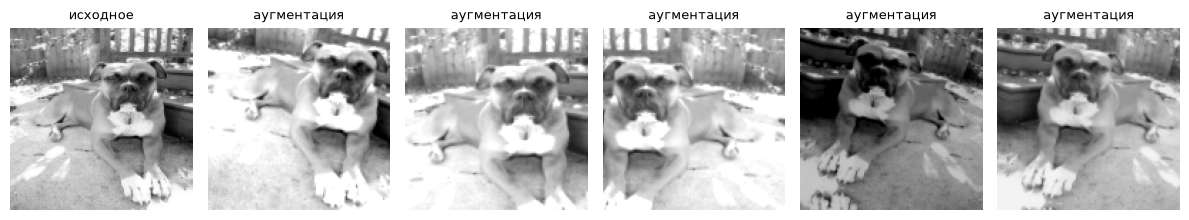

In [11]:
rng = np.random.default_rng(SEED)

def augment(gray, rng):
    h, w = gray.shape
    img = gray[:, ::-1] if rng.random() < 0.5 else gray
    scale = rng.uniform(0.8, 1.0)
    tf = AffineTransform(scale=(1 / scale, 1 / scale), rotation=np.deg2rad(rng.uniform(-15, 15)),
                         translation=(rng.uniform(-0.1, 0.1) * w, rng.uniform(-0.1, 0.1) * h))
    center = AffineTransform(translation=(-w / 2, -h / 2))
    out = warp(img, (center + tf + center.inverse).inverse, mode="reflect")
    out = (out - out.mean()) * rng.uniform(0.7, 1.3) + out.mean() * rng.uniform(0.6, 1.4)  # контраст, яркость
    return np.clip(out, 0, 1)

GRAY_MAIN = [to_gray(load_rgb(f)) for f in main["file"]]

demo = GRAY_MAIN[idx_train[0]]
fig, axes = plt.subplots(1, 6, figsize=(12, 2.4))
axes[0].imshow(demo, cmap="gray", vmin=0, vmax=1); axes[0].set_title("исходное", fontsize=9)
for ax in axes[1:]:
    ax.imshow(augment(demo, rng), cmap="gray", vmin=0, vmax=1); ax.set_title("аугментация", fontsize=9)
for ax in axes:
    ax.axis("off")
fig.tight_layout(); plt.show()

Ошибки лучшей модели: {1: 5, 0: 9} -> дополняется класс «собака» (60 изображений)


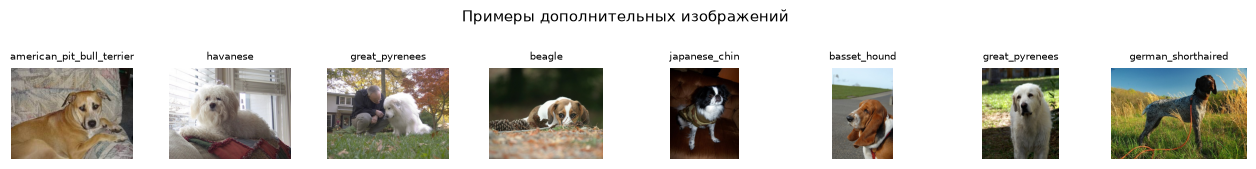

In [12]:
err_by_class = {c: int(((test_df.label == c) & ~test_df.ok).sum()) for c in [1, 0]}
HARD_CLASS = max(err_by_class, key=err_by_class.get)
hard_name = "cat" if HARD_CLASS == 1 else "dog"
GRAY_EXTRA_ALL = [to_gray(load_rgb(f)) for f in extra["file"]]
X_EXTRA_ALL = np.array([hog_features(g) for g in GRAY_EXTRA_ALL])
y_EXTRA_ALL = extra["label"].values
extra_sel = extra[extra["class"] == hard_name].reset_index(drop=True)
print(f"Ошибки лучшей модели: {err_by_class} -> дополняется класс «{name_ru[HARD_CLASS]}» ({len(extra_sel)} изображений)")
show_grid(extra_sel.sample(8, random_state=0), ncols=8, size=1.6, title="Примеры дополнительных изображений",
          caption=lambda r: r["breed"])

In [13]:
N_AUG = 5

def build_train(idx_tr, use_aug, extra_mode, rng):
    # extra_mode: None — без доп. данных; "hard" — только трудный класс; "both" — оба класса (контроль баланса)
    X = [X_all[idx_tr]]; y = [main["label"].values[idx_tr]]
    grays = [GRAY_MAIN[i] for i in idx_tr]; labels = list(main["label"].values[idx_tr])
    if extra_mode:
        sel = np.where(y_EXTRA_ALL == HARD_CLASS)[0] if extra_mode == "hard" else np.arange(len(y_EXTRA_ALL))
        X.append(X_EXTRA_ALL[sel]); y.append(y_EXTRA_ALL[sel])
        grays += [GRAY_EXTRA_ALL[i] for i in sel]; labels += list(y_EXTRA_ALL[sel])
    if use_aug:
        X.append(np.array([hog_features(augment(g, rng)) for g in grays for _ in range(N_AUG)]))
        y.append(np.repeat(labels, N_AUG))
    return np.vstack(X), np.concatenate(y)

CONFIGS = {"Базовая модель": (False, None), "+ аугментация": (True, None),
           f"+ доп. изображения ({name_ru[HARD_CLASS]})": (False, "hard"),
           f"+ аугментация + доп. изображения ({name_ru[HARD_CLASS]})": (True, "hard"),
           "+ доп. изображения обоих классов (контроль)": (False, "both"),
           "+ аугментация + доп. изображения обоих классов": (True, "both")}
base_model = fitted[BEST]

rows, models2 = [], {}
for cname, (ua, ue) in CONFIGS.items():
    Xtr, ytr = build_train(idx_train, ua, ue, np.random.default_rng(SEED))
    m = clone(base_model).fit(Xtr, ytr)
    models2[cname] = m
    pred = m.predict(X_test)
    # Повторные случайные разбиения 80/20 основного набора
    accs = []
    for rep in range(10):
        itr, ite = train_test_split(np.arange(len(main)), test_size=0.2, stratify=main["label"], random_state=100 + rep)
        Xr, yr = build_train(itr, ua, ue, np.random.default_rng(rep))
        accs.append(accuracy_score(main["label"].values[ite], clone(base_model).fit(Xr, yr).predict(X_all[ite])))
    rows.append({"Конфигурация": cname, "Объём обучения": len(ytr),
                 "Accuracy (test)": accuracy_score(y_test, pred), "Precision": precision_score(y_test, pred),
                 "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred),
                 "ROC-AUC": roc_auc_score(y_test, scores_of(m, X_test)),
                 "Accuracy, 10 разбиений": f"{np.mean(accs):.3f} ± {np.std(accs):.3f}", "_acc": np.mean(accs)})

results2 = pd.DataFrame(rows).set_index("Конфигурация")
display(results2.drop(columns="_acc").round(3))

,Объём обучения,Accuracy (test),Precision,Recall,F1,ROC-AUC,"Accuracy, 10 разбиений"
Конфигурация,,,,,,,
Базовая модель,160,0.650,0.625,0.75,0.682,0.718,0.647 ± 0.051
+ аугментация,960,0.650,0.636,0.70,0.667,0.668,0.665 ± 0.071
+ доп. изображения (собака),220,0.525,0.600,0.15,0.240,0.678,0.578 ± 0.049
+ аугментация + доп. изображения (собака),1320,0.600,0.643,0.45,0.529,0.682,0.610 ± 0.062
+ доп. изображения обоих классов (контроль),280,0.650,0.615,0.80,0.696,0.715,0.653 ± 0.058
+ аугментация + доп. изображения обоих классов,1680,0.625,0.600,0.75,0.667,0.705,0.682 ± 0.046


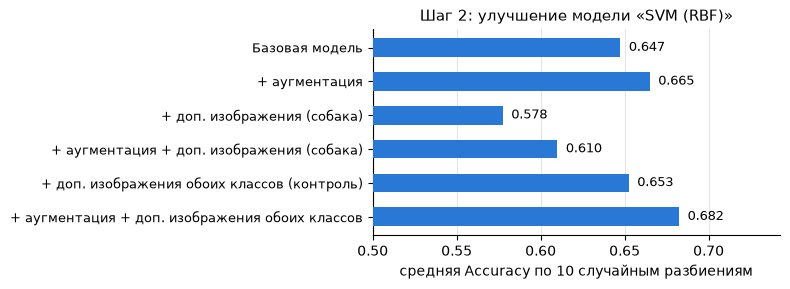

Лучшая конфигурация: + аугментация + доп. изображения обоих классов. Изменилось предсказаний на тесте: 7 (исправлено 3, испорчено 4)


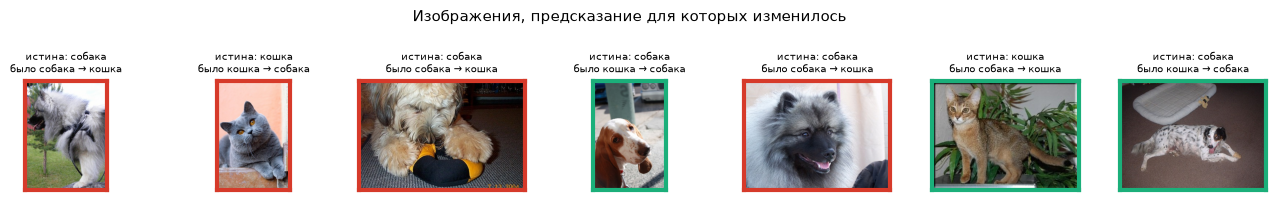

In [14]:
fig, ax = plt.subplots(figsize=(8, 3))
vals = results2["_acc"]
ax.barh(range(len(vals))[::-1], vals.values, color=BLUE, height=0.55, zorder=3)
for i, v in zip(range(len(vals))[::-1], vals.values):
    ax.text(v + 0.005, i, f"{v:.3f}", va="center", fontsize=9)
ax.set_yticks(range(len(vals))[::-1], vals.index, fontsize=9)
ax.set_xlim(0.5, max(vals) + 0.06); ax.grid(axis="x", color="#e5e5e5", zorder=0)
ax.set_xlabel("средняя Accuracy по 10 случайным разбиениям")
ax.set_title(f"Шаг 2: улучшение модели «{BEST}»", fontsize=11)
fig.tight_layout(); plt.show()

best2 = results2["_acc"].idxmax()
pred_new = models2[best2].predict(X_test)
test_df["pred_step2"] = pred_new
changed = test_df[test_df["pred"] != test_df["pred_step2"]]
print(f"Лучшая конфигурация: {best2}. Изменилось предсказаний на тесте: {len(changed)} "
      f"(исправлено {int((changed.pred_step2 == changed.label).sum())}, испорчено {int((changed.pred == changed.label).sum())})")
if len(changed):
    show_grid(changed, ncols=min(8, len(changed)), size=1.9, title="Изображения, предсказание для которых изменилось",
              caption=lambda r: f"истина: {name_ru[r['label']]}\nбыло {name_ru[r['pred']]} → {name_ru[r['pred_step2']]}",
              frame=lambda r: GREEN if r["pred_step2"] == r["label"] else RED)

**Выводы по шагу 2.**

* **Аугментация** в среднем по 10 разбиениям немного повысила точность: 0.647 → 0.665. На фиксированной тестовой выборке точность не изменилась (0.650). Прирост меньше разброса оценок (±0.05–0.07), то есть эффект слабый. Причина: аугментация моделирует сдвиги, повороты и яркость, а анализ ошибок показал, что главные проблемы — поза, пушистость и загромождённый фон. Яркость HOG и так почти не влияет, а новых поз и фонов простые геометрические преобразования не создают.
* **Добавление 60 изображений только «трудного» класса (собак)** ухудшило качество: 0.647 → 0.578, полнота по кошкам на тесте упала с 0.75 до 0.15. Баланс классов сместился (80 кошек против 140 собак), граница SVM сдвинулась, и модель стала относить к собакам почти всё. Ошибки на собаках действительно сократились, но ценой гораздо большего числа ошибок на кошках. Вывод: дополнять данные «трудным» классом нужно, сохраняя баланс, либо с поправкой весов классов (`class_weight`).
* **Контрольный эксперимент** с добавлением 60 изображений обоих классов подтверждает это объяснение: без смещения баланса точность не падает (0.653). В сочетании с аугментацией получен **лучший результат шага 2 — 0.682 ± 0.046** (+3.5 п.п. к базовой модели).
* На фиксированной тестовой выборке лучшая конфигурация изменила 7 предсказаний: 3 ошибки исправлены, 4 новые появились. Это показывает, что при 40 тестовых изображениях выводы стоит делать по повторным разбиениям, а не по одному тесту.
* Итог: аугментация вместе со сбалансированным расширением данных даёт небольшое, но устойчивое улучшение. Для заметного прироста нужно менять сами признаки, например вычислять HOG по области животного, а не по всему кадру, или добавлять признаки цвета и текстуры шерсти. Объём данных и аугментация сами по себе ограничение не снимают.

---
## Шаг 3. Детектор HOG + линейный SVM (+1 балл)

Реализуется схема Dalal & Triggs (CVPR 2005) для обнаружения **головы кошки**:

1. **Окно детектора** 64×64 пикселя; HOG с ячейками 8×8, блоками 2×2, 9 направлениями → $7\cdot 7\cdot 36 = 1764$ признака.
2. **Положительные примеры** — вырезанные по разметке головы кошек из 80 обучающих изображений (рамка дополняется до квадрата), с горизонтальным отражением и небольшими сдвигами.
3. **Отрицательные примеры** — случайные окна разного масштаба из изображений собак обучающей выборки и окна с изображений кошек, не пересекающиеся с головой (IoU < 0.2).
4. **Линейный SVM** обучается на этих окнах.
5. **Поиск сложных отрицательных примеров (hard negative mining):** обученный детектор прогоняется по обучающим изображениям, все ложные срабатывания (окна с положительным откликом, не совпадающие с головой) добавляются в отрицательные примеры, и SVM переобучается — ключевой приём оригинальной работы.
6. **Детекция:** скользящее окно (шаг 8 пикселей) по **пирамиде изображений** (первый уровень увеличен в 1.6 раза, так как часть голов меньше окна 64 пикселя; далее масштаб уменьшается в 1.2 раза на каждом уровне), отклик $w^\top x + b$; затем **подавление немаксимумов** (NMS): из пересекающихся рамок (IoU > 0.3) остаётся одна с наибольшим откликом. Для ускорения HOG считается один раз на каждый уровень пирамиды, и окна вырезаются из готовой сетки блоков.

Качество оценивается **как у детектора**: по метрике $\text{IoU} = \dfrac{|A \cap B|}{|A \cup B|}$ между найденной и истинной рамкой; обнаружение считается верным при IoU ≥ 0.5 (критерий PASCAL VOC). Обучение — на 80 обучающих изображениях кошек (то же разбиение, что в шаге 1), тест — на 20 тестовых изображениях кошек; 20 тестовых изображений собак используются для подсчёта ложных срабатываний.

Обучение: 80 кошек + 80 собак; тест: 20 кошек + 20 собак
Размер головы (большая сторона рамки), пикс.: мин 40, медиана 129, макс 299


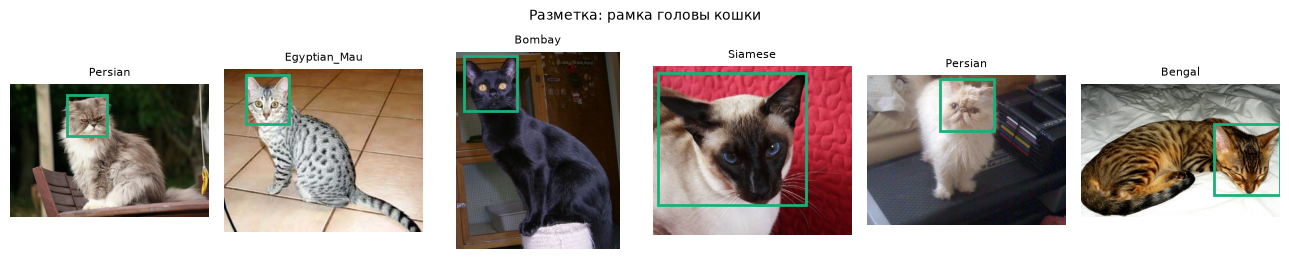

In [15]:
WIN, CELL = 64, 8
DET_HOG = dict(orientations=9, pixels_per_cell=(CELL, CELL), cells_per_block=(2, 2), block_norm="L2-Hys")
BW = WIN // CELL - 1                      # окно = 7×7 блоков
UPSCALE = 1.6                             # первый уровень пирамиды увеличивается, чтобы находить головы меньше 64 пикс.

def gray_full(rel):
    return rgb2gray(load_rgb(rel))

def iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0])); iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0.0

def square_box(b, pad=1.0):
    x0, y0, x1, y1 = b
    cx, cy, s = (x0 + x1) / 2, (y0 + y1) / 2, max(x1 - x0, y1 - y0) * pad
    return [cx - s / 2, cy - s / 2, cx + s / 2, cy + s / 2]

def crop_resize(g, box):
    # Вырезает рамку (с отражением за границами) и приводит к размеру окна
    x0, y0, x1, y1 = [int(round(v)) for v in box]
    pad = max(0, -x0, -y0, x1 - g.shape[1], y1 - g.shape[0])
    gp = np.pad(g, pad, mode="reflect") if pad else g
    patch = gp[y0 + pad:y1 + pad, x0 + pad:x1 + pad]
    return resize(patch, (WIN, WIN), anti_aliasing=True)

def win_hog(patch):
    return hog(patch, **DET_HOG, feature_vector=True)

cats = main[main.label == 1]
det_train = cats[cats.split == "train"].reset_index(drop=True)
det_test = cats[cats.split == "test"].reset_index(drop=True)
dogs_train = main[(main.label == 0) & (main.split == "train")].reset_index(drop=True)
dogs_test = main[(main.label == 0) & (main.split == "test")].reset_index(drop=True)
gt_box = lambda r: [r["xmin"], r["ymin"], r["xmax"], r["ymax"]]

sides = np.maximum(cats.xmax - cats.xmin, cats.ymax - cats.ymin)
print(f"Обучение: {len(det_train)} кошек + {len(dogs_train)} собак; тест: {len(det_test)} кошек + {len(dogs_test)} собак")
print(f"Размер головы (большая сторона рамки), пикс.: мин {sides.min()}, медиана {int(sides.median())}, макс {sides.max()}")

fig, axes = plt.subplots(1, 6, figsize=(13, 2.6))
for ax, (_, r) in zip(axes, det_train.sample(6, random_state=2).iterrows()):
    ax.imshow(load_rgb(r["file"])); b = gt_box(r)
    ax.add_patch(Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, color=GREEN, lw=2))
    ax.axis("off"); ax.set_title(r["breed"], fontsize=8)
fig.suptitle("Разметка: рамка головы кошки", fontsize=10); fig.tight_layout(); plt.show()

In [16]:
rng3 = np.random.default_rng(SEED)

def positive_windows(df):
    feats = []
    for _, r in df.iterrows():
        g = gray_full(r["file"]); sb = square_box(gt_box(r))
        s = sb[2] - sb[0]
        for dx, dy, ds in [(0, 0, 1.0)] + [tuple(rng3.uniform([-0.05, -0.05, 0.95], [0.05, 0.05, 1.08])) for _ in range(2)]:
            cx, cy = (sb[0] + sb[2]) / 2 + dx * s, (sb[1] + sb[3]) / 2 + dy * s
            box = [cx - s * ds / 2, cy - s * ds / 2, cx + s * ds / 2, cy + s * ds / 2]
            p = crop_resize(g, box)
            feats += [win_hog(p), win_hog(p[:, ::-1])]
    return np.array(feats)

def random_negatives(df, per_image, avoid_gt):
    feats = []
    for _, r in df.iterrows():
        g = gray_full(r["file"]); H, W = g.shape; n = 0; tries = 0
        while n < per_image and tries < 200:
            tries += 1
            s = rng3.uniform(WIN, min(H, W)); x0 = rng3.uniform(0, W - s); y0 = rng3.uniform(0, H - s)
            box = [x0, y0, x0 + s, y0 + s]
            if avoid_gt and iou(box, gt_box(r)) >= 0.2:
                continue
            feats.append(win_hog(crop_resize(g, box))); n += 1
    return np.array(feats)

X_pos = positive_windows(det_train)
X_neg = np.vstack([random_negatives(dogs_train, 12, False), random_negatives(det_train, 6, True)])
print(f"Положительных окон: {len(X_pos)}, отрицательных окон: {len(X_neg)}")

Положительных окон: 480, отрицательных окон: 1440


In [17]:
def pyramid_windows(g, scale_step=1.2, upscale=UPSCALE):
    # Все окна по пирамиде: признаки (N×1764) и рамки в координатах исходного изображения
    feats, boxes = [], []
    img = rescale(g, upscale, anti_aliasing=False) if upscale != 1 else g
    factor = 1.0 / upscale                      # пиксель текущего уровня -> пикселей исходного изображения
    while min(img.shape) >= WIN:
        Hb = hog(img, **DET_HOG, feature_vector=False)          # (nby, nbx, 2, 2, 9)
        nby, nbx = Hb.shape[:2]
        if nby >= BW and nbx >= BW:
            win = np.lib.stride_tricks.sliding_window_view(Hb, (BW, BW), axis=(0, 1))  # (ny, nx, 2,2,9, BW, BW)
            win = np.moveaxis(win, (-2, -1), (2, 3))                                    # (ny, nx, BW, BW, 2,2,9)
            ny, nx = win.shape[:2]
            feats.append(win.reshape(ny * nx, -1))
            yy, xx = np.mgrid[0:ny, 0:nx]
            x0 = xx.ravel() * CELL * factor; y0 = yy.ravel() * CELL * factor
            boxes.append(np.stack([x0, y0, x0 + WIN * factor, y0 + WIN * factor], axis=1))
        img = rescale(img, 1 / scale_step, anti_aliasing=True)
        factor *= scale_step
    return np.vstack(feats), np.vstack(boxes)

def nms(boxes, scores, thr=0.3):
    # Жадное подавление немаксимумов (векторизованный расчёт IoU)
    order = np.argsort(-scores); keep = []
    area = (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])
    while len(order):
        i = order[0]; keep.append(i); rest = order[1:]
        ix = np.clip(np.minimum(boxes[i, 2], boxes[rest, 2]) - np.maximum(boxes[i, 0], boxes[rest, 0]), 0, None)
        iy = np.clip(np.minimum(boxes[i, 3], boxes[rest, 3]) - np.maximum(boxes[i, 1], boxes[rest, 1]), 0, None)
        inter = ix * iy
        order = rest[inter / (area[i] + area[rest] - inter) <= thr]
    return keep

def detect(g, clf, score_thr=0.0, upscale=UPSCALE, top_k=300):
    F, B = pyramid_windows(g, upscale=upscale)
    s = clf.decision_function(F)
    idx = np.where(s > score_thr)[0]
    idx = idx[np.argsort(-s[idx])[:top_k]]          # для NMS достаточно нескольких сотен лучших окон
    B, s = B[idx], s[idx]
    keep = nms(B, s)
    return B[keep], s[keep]

# Проверка: признаки окна из пирамиды совпадают с HOG вырезанного фрагмента (с точностью до краевых эффектов)
g0 = gray_full(det_train.loc[0, "file"])
F0, B0 = pyramid_windows(g0, upscale=1.0)
k = len(F0) // 3
x0, y0 = int(B0[k][0]), int(B0[k][1])
direct = win_hog(g0[y0:y0 + WIN, x0:x0 + WIN]) if B0[k][2] - B0[k][0] == WIN else None
print("Окон на одном изображении (все уровни пирамиды):", len(F0))
if direct is not None:
    print("Корреляция признаков окна и прямого HOG фрагмента:", round(np.corrcoef(F0[k], direct)[0, 1], 3))

Окон на одном изображении (все уровни пирамиды): 2775
Корреляция признаков окна и прямого HOG фрагмента: 0.988


In [18]:
def train_svm(Xp, Xn, C=0.01):
    X = np.vstack([Xp, Xn]); y = np.r_[np.ones(len(Xp)), np.zeros(len(Xn))]
    return LinearSVC(C=C, max_iter=50000, class_weight="balanced").fit(X, y)

def mine_hard_negatives(clf, max_per_image=15):
    hard = []
    for df, has_obj in [(dogs_train, False), (det_train, True)]:
        for _, r in df.iterrows():
            F, B = pyramid_windows(gray_full(r["file"]))
            s = clf.decision_function(F)
            idx = np.where(s > -0.2)[0]
            if has_obj:
                idx = [i for i in idx if iou(B[i], gt_box(r)) < 0.3]
            idx = sorted(idx, key=lambda i: -s[i])[:max_per_image]
            hard.append(F[idx])
    return np.vstack(hard)

t0 = time.time()
svm0 = train_svm(X_pos, X_neg)
X_hard1 = mine_hard_negatives(svm0)
svm1 = train_svm(X_pos, np.vstack([X_neg, X_hard1]))
X_hard2 = mine_hard_negatives(svm1)
svm2 = train_svm(X_pos, np.vstack([X_neg, X_hard1, X_hard2]))
print(f"Сложных отрицательных окон: раунд 1 — {len(X_hard1)}, раунд 2 — {len(X_hard2)}; время {time.time() - t0:.0f} с")

Сложных отрицательных окон: раунд 1 — 2400, раунд 2 — 1203; время 335 с


In [19]:
def evaluate_detector(clf, iou_thr=0.5):
    # Для тестовых кошек: лучшая рамка (макс. отклик) и её IoU; для AP — все рамки по всем 40 изображениям
    rows, all_dets = [], []
    for df, has_obj in [(det_test, True), (dogs_test, False)]:
        for _, r in df.iterrows():
            B, s = detect(gray_full(r["file"]), clf, score_thr=-1.0)
            for b, sc in zip(B, s):
                all_dets.append((sc, r["file"], b))
            if has_obj:
                best = B[0] if len(B) else None
                rows.append({"file": r["file"], "breed": r["breed"], "box": best,
                             "score": s[0] if len(s) else np.nan,
                             "IoU": iou(best, gt_box(r)) if best is not None else 0.0})
            else:
                rows_neg = (s > 0).sum()
                rows.append({"file": r["file"], "breed": r["breed"], "box": B[0] if len(B) else None,
                             "score": s[0] if len(s) else np.nan, "IoU": np.nan, "fp": int(rows_neg)})
    res = pd.DataFrame(rows)
    # Average Precision (PASCAL VOC, все точки)
    gts = {r["file"]: gt_box(r) for _, r in det_test.iterrows()}
    used, tp = set(), []
    for sc, f, b in sorted(all_dets, key=lambda t: -t[0]):
        hit = f in gts and f not in used and iou(b, gts[f]) >= iou_thr
        if hit:
            used.add(f)
        tp.append(hit)
    tp = np.array(tp, dtype=float)
    rec = np.cumsum(tp) / len(gts); prec = np.cumsum(tp) / np.arange(1, len(tp) + 1)
    mprec = np.maximum.accumulate(prec[::-1])[::-1]
    ap = np.sum(np.diff(np.r_[0, rec]) * mprec)
    return res, ap, rec, prec

det_rows, curves = [], {}
for name, clf in [("SVM без hard negative mining", svm0), ("SVM + 1 раунд hard negatives", svm1),
                  ("SVM + 2 раунда hard negatives", svm2)]:
    res, ap, rec, prec = evaluate_detector(clf)
    cat_res = res[res["IoU"].notna()]
    curves[name] = (rec, prec)
    det_rows.append({"Детектор": name, "Средний IoU (лучшая рамка)": cat_res["IoU"].mean(),
                     "Медианный IoU": cat_res["IoU"].median(),
                     "Доля IoU ≥ 0.5": (cat_res["IoU"] >= 0.5).mean(),
                     "Ложных рамок на изобр. собаки (отклик > 0)": res["fp"].mean(),
                     "AP@0.5": ap, "_res": res})
det_table = pd.DataFrame(det_rows).set_index("Детектор")
display(det_table.drop(columns="_res").round(3))

,Средний IoU (лучшая рамка),Медианный IoU,Доля IoU ≥ 0.5,Ложных рамок на изобр. собаки (отклик > 0),AP@0.5
Детектор,,,,,
SVM без hard negative mining,0.346,0.125,0.40,39.95,0.363
SVM + 1 раунд hard negatives,0.381,0.334,0.50,3.20,0.250
SVM + 2 раунда hard negatives,0.388,0.368,0.45,0.65,0.382


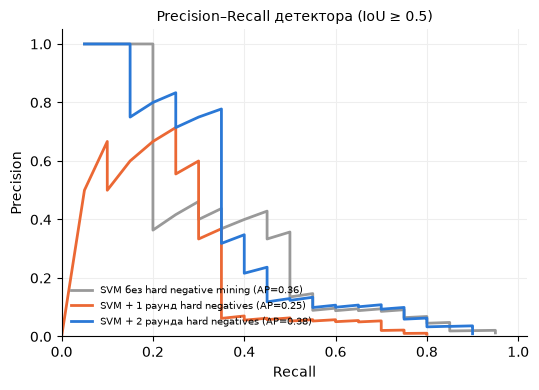

In [20]:
fig, ax = plt.subplots(figsize=(5.5, 4))
for (name, (rec, prec)), c in zip(curves.items(), ["#999999", ORANGE, BLUE]):
    ax.plot(rec, prec, color=c, lw=2, label=f"{name} (AP={det_table.loc[name, 'AP@0.5']:.2f})")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.set_xlim(0, 1.02); ax.set_ylim(0, 1.05)
ax.grid(color="#eee"); ax.legend(fontsize=7.5, frameon=False, loc="lower left")
ax.set_title("Precision–Recall детектора (IoU ≥ 0.5)", fontsize=10)
fig.tight_layout(); plt.show()

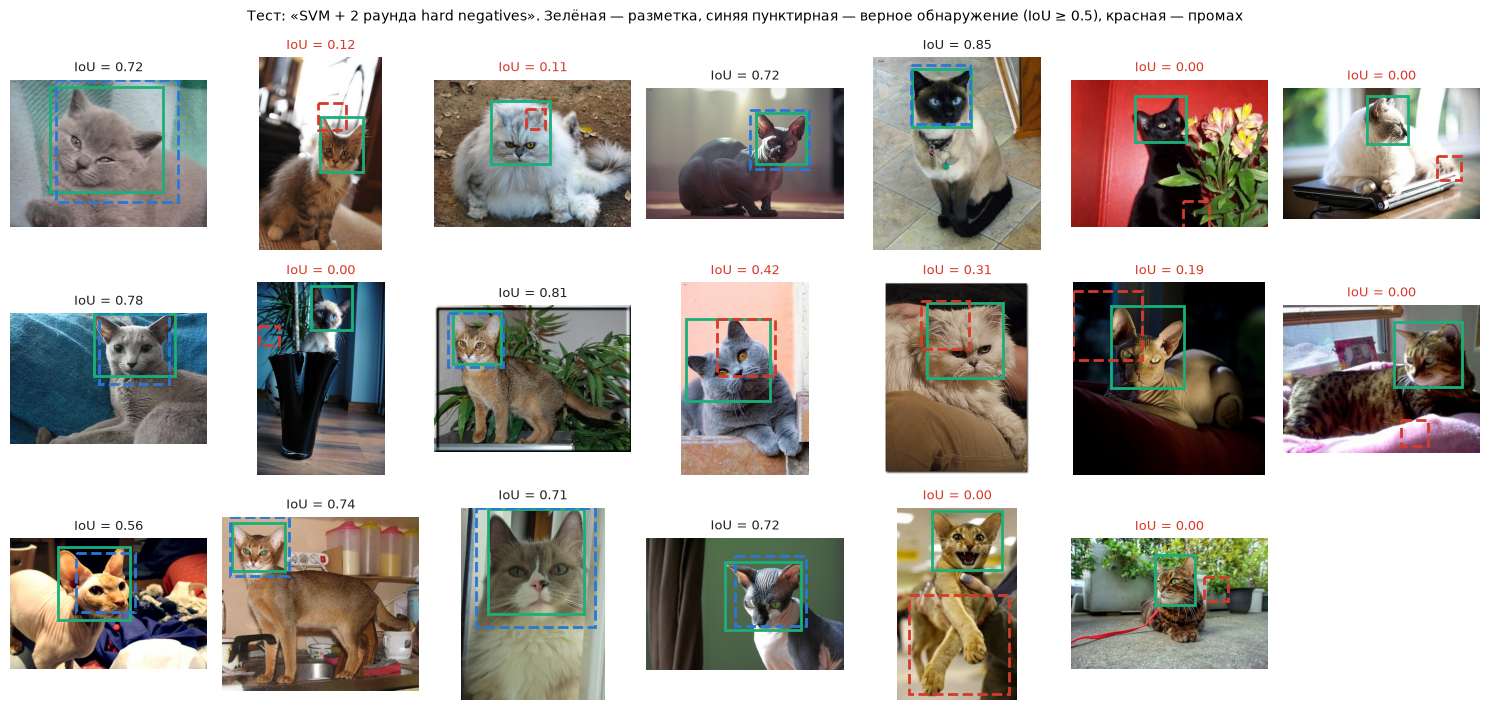

In [21]:
BEST_DET = det_table["AP@0.5"].idxmax()
res = det_table.loc[BEST_DET, "_res"]
cat_res = res[res["IoU"].notna()].reset_index(drop=True)

fig, axes = plt.subplots(3, 7, figsize=(15, 7.2))
for ax in axes.ravel():
    ax.axis("off")
for ax, (_, r) in zip(axes.ravel(), cat_res.iterrows()):
    row = det_test[det_test.file == r["file"]].iloc[0]
    ax.imshow(load_rgb(r["file"])); g = gt_box(row)
    ax.add_patch(Rectangle((g[0], g[1]), g[2] - g[0], g[3] - g[1], fill=False, color=GREEN, lw=2))
    if r["box"] is not None:
        b = r["box"]
        ax.add_patch(Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False,
                               color=BLUE if r["IoU"] >= 0.5 else RED, lw=2, ls="--"))
    ax.set_title(f"IoU = {r['IoU']:.2f}", fontsize=9, color="#222" if r["IoU"] >= 0.5 else RED)
fig.suptitle(f"Тест: «{BEST_DET}». Зелёная — разметка, синяя пунктирная — верное обнаружение (IoU ≥ 0.5), красная — промах",
             fontsize=10)
fig.tight_layout(); plt.show()

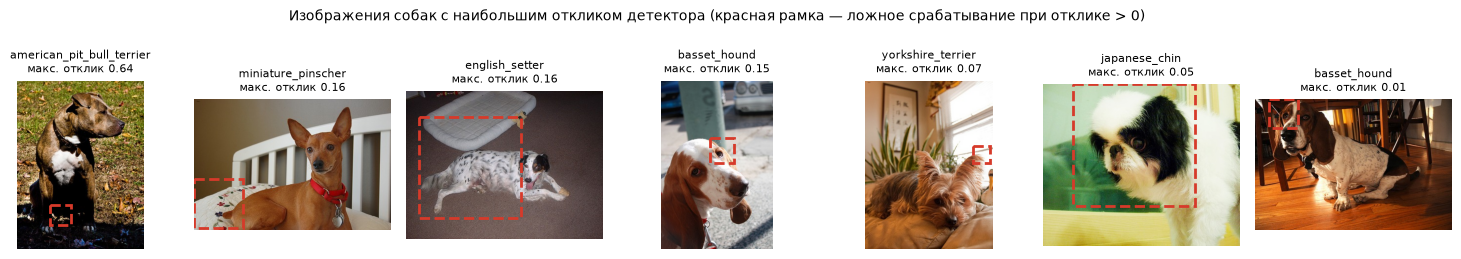

Распределение IoU на тестовых кошках:
IoU
(-0.01, 0.1]    6
(0.1, 0.3]      3
(0.3, 0.5]      2
(0.5, 0.7]      1
(0.7, 1.0]      8


In [22]:
dog_res = res[res["IoU"].isna()].reset_index(drop=True)
show_dogs = dog_res.sort_values("score", ascending=False).head(7)
fig, axes = plt.subplots(1, 7, figsize=(15, 2.6))
for ax, (_, r) in zip(axes, show_dogs.iterrows()):
    ax.imshow(load_rgb(r["file"])); ax.axis("off")
    if r["box"] is not None and r["score"] > 0:
        b = r["box"]; ax.add_patch(Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1], fill=False, color=RED, lw=2, ls="--"))
    ax.set_title(f"{r['breed']}\nмакс. отклик {r['score']:.2f}", fontsize=8)
fig.suptitle("Изображения собак с наибольшим откликом детектора (красная рамка — ложное срабатывание при отклике > 0)", fontsize=10)
fig.tight_layout(); plt.show()

print("Распределение IoU на тестовых кошках:")
print(pd.cut(cat_res["IoU"], [-0.01, 0.1, 0.3, 0.5, 0.7, 1.0]).value_counts().sort_index().to_string())

**Выводы по детектору HOG + линейный SVM.**

* **Поиск сложных отрицательных примеров решающе важен для отсечения ложных срабатываний.** Без него детектор выдаёт в среднем 40 ложных рамок с положительным откликом на каждом изображении собаки, после первого раунда — 3.2, после второго — 0.65. Это главный эффект процедуры из работы Dalal & Triggs.
* **Качество локализации** лучшего детектора (2 раунда hard negative mining): голова найдена с IoU ≥ 0.5 на 9 из 20 тестовых кошек (45 %), средний IoU 0.39, AP@0.5 = 0.38. Распределение бимодальное: 8 изображений имеют IoU > 0.7 (рамка найдена точно), 6 — IoU < 0.1 (лучшая рамка вообще не на голове). Промежуточных случаев мало: детектор либо находит голову уверенно, либо ошибается полностью.
* **Голова находится точно**, когда она снята анфас, имеет чёткий контур и хорошо различимые уши, а фон однородный: сиамская кошка, сфинксы, русская голубая, крупные портреты.
* **Детектор промахивается** в следующих случаях: голова в профиль или повёрнута (котёнок, смотрящий вверх; кошка на ноутбуке у окна); пушистые породы с размытым контуром (персидская: рамка смещается на фрагмент шерсти); тёмная кошка на тёмном или ярком фоне (бомбейская на красной стене); маленькая голова на текстурированном уличном фоне; кошка с открытой пастью. В этих случаях максимальный отклик даёт небольшое окно на участке с похожей текстурой (шерсть, листья, края мебели).
* Ложные срабатывания на собаках тоже возникают на текстуре шерсти и на мордах с похожей формой: мелкие собаки с острыми ушами, чёрно-белая морда японского хина.
* Немонотонность AP (0.36 → 0.25 → 0.38 по раундам) объясняется малым тестом из 20 голов: перестановка нескольких рамок по отклику заметно меняет AP. Устойчивая тенденция одна — резкое падение числа ложных срабатываний.
* Ограничения подхода — одно жёсткое окно 64×64 с одной ориентацией и только 80 обучающих голов. Классический HOG-детектор хорошо работает для объектов с устойчивой формой (пешеходы в работе Dalal & Triggs). Голова кошки сильно меняется с ракурсом, поэтому для неё нужно больше данных, несколько моделей под разные ракурсы (как в DPM) или нелинейный классификатор.

---
## Итоговые выводы

1. **HOG-признаки различают кошек и собак** заметно лучше случайного угадывания: лучшая точность ≈ 0.69–0.70 (SVM с RBF-ядром по повторной перекрёстной проверке, логистическая регрессия и линейный SVM на тесте). Четыре из пяти моделей статистически равноценны; kNN для высокоразмерных HOG-признаков непригоден.
2. **Ошибки определяются геометрией и фоном, а не освещением**: путаются собаки с «кошачьим» силуэтом (острые уши, узкая морда, поза лёжа, домашний фон) и пушистые кошки или кошки на загромождённом фоне. Яркость, контраст и размер животного в кадре у трудных и лёгких изображений практически одинаковы.
3. **Улучшения шага 2** дают небольшой прирост: аугментация вместе со сбалансированным добавлением данных — 0.647 → 0.682. Добавление изображений только одного «трудного» класса без балансировки ухудшает модель (0.578) из-за смещения баланса классов.
4. **Детектор HOG + линейный SVM** по схеме Dalal & Triggs точно находит голову кошки на 45 % тестовых изображений (IoU ≥ 0.5, AP = 0.38). Поиск сложных отрицательных примеров сокращает ложные срабатывания примерно в 60 раз (с 40 до 0.65 на изображение собаки). Детектор надёжен для голов анфас с чётким контуром и ошибается на профилях, пушистых и тёмных кошках.
5. Общий вывод: классические методы на основе HOG дают интерпретируемый и быстрый, но ограниченный по качеству результат на задаче с близкими по форме классами и высокой изменчивостью позы.